In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import joblib

In [ ]:
# 1. LOAD DATA & MODEL
# load the test data (real data) to explain predictions
X_test = pd.read_csv('../data/X_test.csv')
y_test = pd.read_csv('../data/y_test.csv')

# Load the LightGBM model since it gave the best performance based on AUC and precision.
# If a saved version of the model is available, it can be loaded directly.
# Otherwise, the model is retrained here to ensure the results can be reproduced.
from lightgbm import LGBMClassifier
X_train = pd.read_csv('../data/X_train_resampled.csv')
y_train = pd.read_csv('../data/y_train_resampled.csv').values.ravel()

model = LGBMClassifier(random_state=42, verbose=-1)
model.fit(X_train, y_train)

LGBMClassifier(random_state=42, verbose=-1)

In [3]:
# 2. CALCULATE SHAP VALUES
# SHAP explains "margin" output, which is the raw score before probability
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# Handle different SHAP versions (sometimes returns list, sometimes array)
# LightGBM binary usually returns [class0_shap, class1_shap]. We want Class 1 (Bad Loan).
if isinstance(shap_values, list):
    shap_values = shap_values[1]

print("SHAP values calculated. Shape:", shap_values.shape)

SHAP values calculated. Shape: (2993, 113)


c:\Users\Yahya\anaconda3\envs\myenv\Lib\site-packages\shap\explainers\_tree.py:587: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


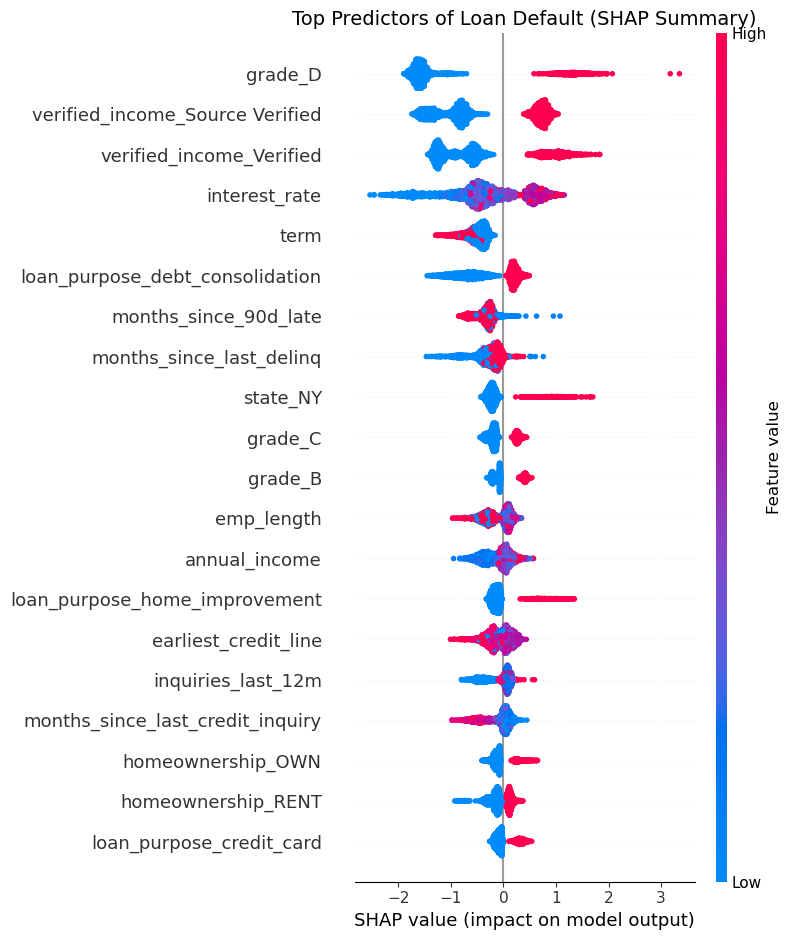

In [ ]:
# 3. GLOBAL IMPORTANCE (Summary Plot)
# This shows WHICH features matter most across all customers
plt.figure(figsize=(10, 8))
plt.title("Top Predictors of Loan Default (SHAP Summary)", fontsize=14)
shap.summary_plot(shap_values, X_test, show=False)
plt.savefig('shap_summary.png', bbox_inches='tight')
plt.show()

<Figure size 1000x600 with 0 Axes>

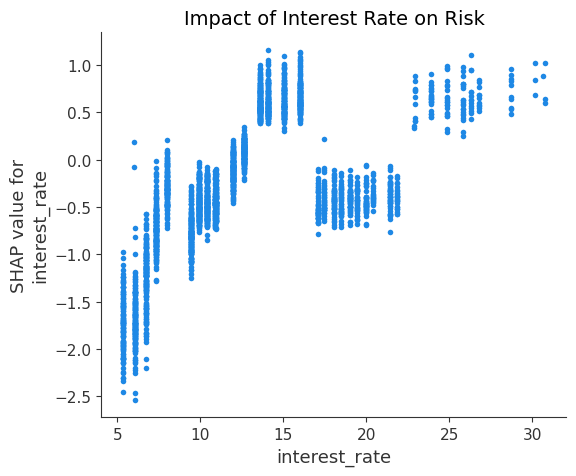

In [ ]:
# 4. DEPENDENCE PLOT (Feature Relationship)
# HOW 'interest_rate' affects risk.
# Does higher interest rate always mean higher risk?
plt.figure(figsize=(10, 6))
shap.dependence_plot("interest_rate", shap_values, X_test, interaction_index=None, show=False)
plt.title("Impact of Interest Rate on Risk", fontsize=14)
plt.savefig('shap_dependence_interest.png', bbox_inches='tight')
plt.show()

Base Value used for plot: 0.4587902698950259


SUCCESS: Local explanation saved to 'shap_local_explanation.png'


<Figure size 2000x300 with 0 Axes>

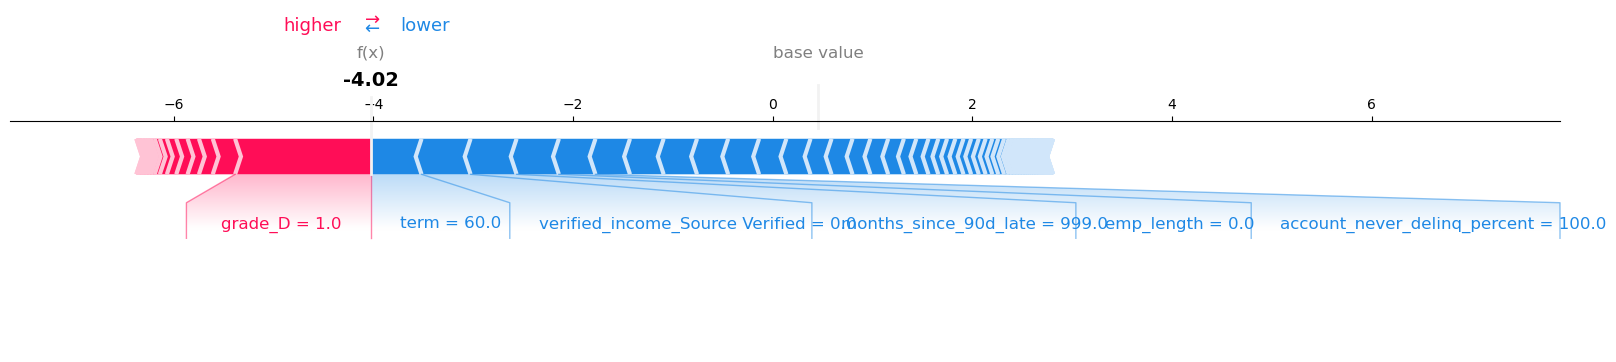

In [ ]:
# 5. LOCAL EXPLANATION (Force Plot)

# FIX: Handle expected_value whether it's a list or a single number
if isinstance(explainer.expected_value, (list, np.ndarray)):
    # If it's a list (Class 0, Class 1), take Class 1
    base_value = explainer.expected_value[1] 
else:
    # If it's just a single number, use it directly
    base_value = explainer.expected_value

print(f"Base Value used for plot: {base_value}")

# Initialize JS (needed if running this interactively, beneficial to keep)
shap.initjs()

# Generate the plot
# use matplotlib=True so save it as a static image
plt.figure(figsize=(20, 3)) 
shap.force_plot(
    base_value, 
    shap_values[0,:], 
    X_test.iloc[0,:], 
    matplotlib=True,
    show=False
)

plt.savefig('shap_local_explanation.png', bbox_inches='tight', dpi=300)
print("SUCCESS: Local explanation saved to 'shap_local_explanation.png'")